# Exp 13: sanity check with linear collection costs on exp_12's instances

exp_13 reruns exp_12's sweep (compact_window_instances.csv) with collection costs that respect the stylized model (§3.2), in two arms:
- **zero**: `truck_cost_per_m = 0`, so c_f = 0 (the CSV's own c_f);
- **star**: a star road graph with one private spur per farmer, so collecting a set S costs Σ_{f∈S} c_f, with c_f each farmer's real round-trip cost from exp_12.

exp_12 (the real road tree, labelled **road** below) is included for comparison. Instances, seeds, high types, grid and refinement are identical to exp_12.

**What should hold.** With linear costs the simulated instance *is* the stylized model, so the solver should reproduce the stylized (S-PFP) optimum, which Lemma 1 gives in closed form (EC9):
1. **Matched set**: at every solved ε_h, the solver's (high, low) matched counts are one of the model's optimal compositions.
2. **Profit**: the solver's platform profit equals the model's optimum × σ_ℓ, in *both* arms (c_f cancels from (6a)).
3. **Switch points**: the observed switches land on ε_h⁻ and ε_h⁺ (Prop 3, cases ii–iii) and, past `L`, on ε̄_h from (EC4) (cases iv–v).

## Summary of findings

All 64 exp_13 jobs (32 instances × 2 arms, about 2,470 solves), with exp_12 (road) for the same 32 instances. Every sweep is complete and every switch is bisected to the 0.025 tolerance.

- **With linear collection costs the solver reproduces the stylized model exactly, in both arms.** At every solved point (1,237 zero, 1,229 star), the matched (high, low) counts are a stylized (S-PFP) optimum, and the platform profit equals the stylized optimal profit (largest relative error 7e-8).
- **Every switch is where Prop 3 puts it.** All 32 onsets and 32 exits per arm bracket ε_h⁻ and ε_h⁺. All 25 saturated onsets per arm (the instances with finite ε̄_h) bracket ε̄_h from (EC4), at offsets within ±0.013.
- **No unexplained matches.** No linear-cost point has high types matched outside the predicted regions, and none of these instances is a knife edge (ε_ℓ = ε_ℓ^s). The 7 instances with ε̄_h = ∞ stay efficient past `L`.
- **Zero and star agree.** They make the same choice at 98.9% of shared ε_h points. Every difference is between two optimal compositions, i.e. a tie-break (75 tie points per arm).
- **The road arm (exp_12) is the only one that deviates.**
  - None of its 32 onsets brackets ε_h⁻. All are early, by a median of 0.54.
  - Only 2 of 24 uncensored exits bracket ε_h⁺, and only 2 of 18 saturated onsets bracket ε̄_h.
  - Its matched set is a stylized optimum at only 71% of points.
- **Conclusion:** as in exp_11, the instance mapping and the solver are correct on the compact instances, and exp_12's departures from Prop 3 come from the non-additivity of real routing costs.

In [1]:
from pathlib import Path
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import subprocess
import sys

In [2]:
RESULTS_13 = Path("../results/exp_13")
RESULTS_12 = Path("../results/exp_12")
FIG_DIR = Path("../figures/exp_13")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ARMS = ["zero", "star", "road"]          # road = exp_12, the real road tree
ARM_LABELS = {"zero": "zero cost (linear c_f = 0)", "star": "star (linear c_f)", "road": "road (exp_12)"}
PROFIT_TOL = 1e-6                        # relative
SWITCH_TOL = 1e-6                        # a prediction "inside" a bracket, up to rounding

# light-mode chart tokens; categorical slots 1-3 validate all-pairs (aqua is sub-3:1, so
# every chart also has a legend and a table view)
SURFACE, INK, INK_SECONDARY, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
ARM_COLORS = {"zero": "#2a78d6", "star": "#eb6834", "road": "#1baf7a"}
MATCH_NONE, MATCH_SOME, MATCH_ALL = GRID, "#86b6ef", "#184f95"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_SECONDARY, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})

## Load

In [3]:
def load_jobs(paths, arm_of):
    jobs = []
    for file in sorted(paths):
        with gzip.open(file, "rt", encoding="utf-8") as f:
            jobs.append((arm_of(file), json.load(f)))
    return jobs

jobs = load_jobs(RESULTS_13.rglob("*.json.gz"), lambda file: file.parent.parent.name)
instances_13 = {payload["instance_id"] for _, payload in jobs}
# exp_12 counterparts (real road tree), for the same instances only
jobs += [
    (arm, payload)
    for arm, payload in load_jobs(RESULTS_12.rglob("*.json.gz"), lambda file: "road")
    if payload["instance_id"] in instances_13
]

windows, cost_rows, point_rows = {}, [], []
for arm, payload in jobs:
    instance_id = payload["instance_id"]
    # utils.encode_nonfinite saves NaN and ±inf as strings
    windows[instance_id] = {k: float(v) if v in ("NaN", "Infinity", "-Infinity") else v for k, v in payload["window"].items()}
    sigma_ell = payload["experiment_metadata"]["constants"]["sigma_ell"]
    high_ids = set(payload["high_ids"])
    if arm != "road":
        costs = payload["collection_costs"]
        cost_rows.append({"arm": arm, "instance": instance_id, "n_runs": payload["n_runs"],
                          **{k: v for k, v in costs.items() if k not in ("c_f", "routing_mode")}})
    for run in payload["runs"]:
        primary = run["summary"]["platform_solve_result"]["primary_result"]
        matched = set(primary["selected_intermediaries"])
        point_rows.append({
            "arm": arm, "instance": instance_id, "eps_h": run["eps_h"], "phase": run["phase"].split("_")[0],
            "n_high": len(matched & high_ids), "n_low": len(matched - high_ids),
            "profit": primary["platform_profit"], "sigma_ell": sigma_ell,
            "wall_time": run["wall_time"], "rel_gap": run["summary"]["rel_gap"],
        })

points = pd.DataFrame(point_rows).sort_values(["instance", "arm", "eps_h"]).reset_index(drop=True)
print(f"{len(jobs)} jobs: " + ", ".join(f"{arm} {n}" for arm, n in pd.Series([a for a, _ in jobs]).value_counts().items()))
print(f"instances: {sorted(instances_13)}; {len(points)} solved points; max rel_gap {points['rel_gap'].max():.1e}")
points.groupby("arm")["wall_time"].describe()[["count", "mean", "50%", "max"]]

96 jobs: star 32, zero 32, road 32
instances: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]; 3812 solved points; max rel_gap 9.6e-05


,count,mean,50%,max
arm,,,,
road,1346.0,567.724802,466.081765,2264.589992
star,1229.0,190.255087,168.989798,701.008714
zero,1237.0,236.779748,196.598893,762.428822


### Collection costs

Each exp_13 job verified its costs before solving: the zero arm has c_f = 0, the star arm is additive (cost of a set = sum of its farmers' costs), and Assumption 1(f), e_ℓ + max c_f < p, holds.

In [4]:
pd.DataFrame(cost_rows).set_index(["arm", "instance"]).round(2)

n_runs  truck_cost_per_m    c_f_min   c_f_mean    c_f_max  \
arm  instance                                                              
star 1             40              2.62   70985.84  325307.79  615195.37   
     2             42              2.62   85042.35  422834.71  646247.69   
     3             40              2.62  139192.86  377549.70  594149.05   
     4             33              2.62   63750.77  466287.27  931639.21   
     5             34              2.62   47161.49  253891.71  636554.61   
...               ...               ...        ...        ...        ...   
zero 6             34              0.00       0.00       0.00       0.00   
     7             42              0.00       0.00       0.00       0.00   
     8             39              0.00       0.00       0.00       0.00   
     9             39              0.00       0.00       0.00       0.00   
     10            39              0.00       0.00       0.00       0.00   

               linearity_max_violation  assumption_1f_slack  
arm  instance                                                
star 1                             0.0           1631137.97  
     2                             0.0           1666752.31  
     3                             0.0           1652184.28  
     4                             0.0           1181360.79  
     5                             0.0           1609778.73  
...                                ...                  ...  
zero 6                             0.0           2246333.33  
     7                             0.0           2313000.00  
     8                             0.0           2113000.00  
     9                             0.0           2246333.33  
     10                            0.0           2246333.33  

[64 rows x 7 columns]

## Predicted thresholds

ε_h⁻ and ε_h⁺ are the roots of (EC3) and ε̄_h is (EC4); they are checked against the values exp_12/exp_13 computed and saved with each job.

In [5]:
def thresholds(w):
    # Prop 3 window (cases ii-iii) and the saturated threshold (EC4, cases iv-v), in tons
    a = w["n_l"] + w["eps_l"]
    L = w["K"] - w["n_h"]
    M = w["T_l"] * w["n_l"] / w["T_h"]
    rho = w["sigma_h"] / w["sigma_l"]
    disc = (M + a) ** 2 - 4 * M * rho * a
    lo, hi = ((M + a - np.sqrt(disc)) / 2, (M + a + np.sqrt(disc)) / 2) if disc >= 0 else (np.nan, np.nan)

    K, n_h, n_l, T_h, T_l = w["K"], w["n_h"], w["n_l"], w["T_h"], w["T_l"]
    s_l, s_h = w["sigma_l"], w["sigma_h"]
    F = T_l * n_l + T_h * n_h
    e_l = s_l / a
    eps_l_s = K * (F - T_h * K) * s_l / (F * s_h - T_h * K * s_l) - n_l
    bar = min(L + n_h * (s_h - s_l) / (K * e_l - s_l),
              T_l * n_l * s_h / ((F - T_h * K) * e_l + T_h * s_l)) if w["eps_l"] < eps_l_s else np.inf
    return {"L": L, "eps_h_minus": lo, "eps_h_plus": hi, "eps_h_bar": bar}

pred = pd.DataFrame({i: thresholds(w) for i, w in windows.items()}).T
pred.index.name = "instance"

# cross-check against the thresholds exp_12/exp_13 derived and saved with each job
saved = pd.DataFrame({i: {c: windows[i][c] for c in ["L", "eps_h_minus", "eps_h_plus", "eps_h_bar"]} for i in windows}).T.astype(float)
diff = (pred.astype(float) - saved).abs().replace(np.nan, 0.0)
diff[np.isinf(pred.astype(float)) & np.isinf(saved)] = 0.0
print(f"max |notebook − saved| threshold: {diff.to_numpy().max():.1e}")
pred.round(4)

max |notebook − saved| threshold: 0.0e+00


,L,eps_h_minus,eps_h_plus,eps_h_bar
instance,,,,
1,7.0,4.4000,6.6000,7.2600
2,7.0,5.3072,6.6928,7.1040
3,7.0,4.4000,6.6000,7.2600
4,4.0,2.7000,3.8000,4.1040
5,5.0,3.5333,4.8000,5.0880
6,5.0,3.5333,4.8000,5.0880
7,7.0,5.3072,6.6928,7.1040
8,5.0,2.7638,4.7362,5.2360
9,5.0,3.7576,4.7424,5.0914


## Check 1 and 2: matched set and profit at every solved point

With x_h high types and `min_trucks` − x_h low types matched, Lemma 1 (EC9) reduces (S-PFP) to a one-dimensional problem in the top farmer margin v̄:

  Π(x_h, v̄) = |F| v̄ − |T_ℓ| [A_ℓ v̄ − σ_ℓ]⁺ − (|T_h| + δ_h(|T_h| − x_h)) [A_h v̄ − σ_h]⁺ − (N − x_h) σ_ℓ − x_h σ_h,

with A_ℓ = n_ℓ + ε_ℓ, A_h = min(n_h + ε_h, K), δ_h = (n_h + ε_h − K)⁺ / min(n_h, K − ε_h), N = `min_trucks`, and, when some high type is unmatched, the stability bound ε_h v̄ ≤ σ_h. Its maximum is at a kink e_ℓ = σ_ℓ/A_ℓ, e_h = σ_h/A_h, or σ_h/ε_h. `model_optimal` lists every optimal composition [n_high, n_low] (within `TIE_TOL`); `tie` marks points where more than one is optimal.

The checks apply to the linear-cost arms; the road arm is shown for comparison only.

In [6]:
TIE_TOL = 1e-7  # relative; compositions within this of the best are all optimal


def profit_closed_form(w, eps_h, x_h):
    # (S-PFP) profit in sigma_l units with x_h high types matched: max over vbar of (EC9)
    K, n_h, n_l, eps_l, T_h, T_l = (float(w[c]) for c in ["K", "n_h", "n_l", "eps_l", "T_h", "T_l"])
    s_l, s_h, N = float(w["sigma_l"]), float(w["sigma_h"]), float(w["min_trucks"])
    F = T_l * n_l + T_h * n_h
    A_l, A_h = n_l + eps_l, min(n_h + eps_h, K)
    delta = max(0.0, n_h + eps_h - K) / min(n_h, K - eps_h)

    def Pi(v):
        return (F * v - T_l * max(A_l * v - s_l, 0) - (T_h + delta * (T_h - x_h)) * max(A_h * v - s_h, 0)
                - (N - x_h) * s_l - x_h * s_h)

    upper = s_h / eps_h if x_h < T_h and eps_h > 0 else np.inf
    return max(Pi(v) for v in (s_l / A_l, s_h / A_h, upper) if 0 <= v <= upper)


def model_optimum(w, eps_h):
    # optimal profit and every optimal composition [n_high, n_low]
    T_h, N = int(w["T_h"]), int(w["min_trucks"])
    values = {x_h: profit_closed_form(w, eps_h, x_h) for x_h in range(T_h + 1)}
    best = max(values.values())
    optimal = [[x_h, N - x_h] for x_h, v in values.items() if v >= best - TIE_TOL * max(1.0, abs(best))]
    return best, optimal


rows = []
for r in points.itertuples():
    best, optimal = model_optimum(windows[r.instance], r.eps_h)
    rows.append({
        "model_optimal": optimal,
        "tie": len(optimal) > 1,
        "matched_ok": [r.n_high, r.n_low] in optimal,
        "model_profit": best * r.sigma_ell,
    })

points = pd.concat([points.drop(columns=[c for c in ["model_optimal", "tie", "matched_ok", "model_profit"] if c in points]),
                    pd.DataFrame(rows, index=points.index)], axis=1)
points["profit_rel_err"] = (points["profit"] - points["model_profit"]).abs() / points["model_profit"].abs().clip(lower=1.0)
points["profit_ok"] = points["profit_rel_err"] <= PROFIT_TOL

summary = points.groupby("arm").agg(
    points=("eps_h", "size"),
    matched_ok=("matched_ok", "mean"),
    profit_ok=("profit_ok", "mean"),
    max_profit_rel_err=("profit_rel_err", "max"),
    ties=("tie", "sum"),
).reindex([a for a in ARMS if a in points["arm"].unique()])
summary

,points,matched_ok,profit_ok,max_profit_rel_err,ties
arm,,,,,
zero,1237,1.000000,1.0,7.415053e-08,75
star,1229,1.000000,1.0,5.995992e-08,75
road,1346,0.711738,0.0,2.924422e+05,75


In [7]:
print("Linear-cost points that fail either check:")
points.query("arm != 'road' and (not matched_ok or not profit_ok)")[
    ["arm", "instance", "eps_h", "phase", "n_high", "n_low", "model_optimal", "profit", "model_profit", "profit_rel_err"]
]

Linear-cost points that fail either check:


,arm,instance,eps_h,phase,n_high,n_low,model_optimal,profit,model_profit,profit_rel_err


## Check 3: switch points

Each observed switch is a bracket `(eps_before, eps_after]` of consecutive solved points where the matched high-type count changes from zero to positive (onset) or back (exit), within the unsaturated regime ε_h ≤ `L`; `sat_onset` is the first switch to a positive count above `L`. `contains_prediction` is whether the predicted threshold lies in the closed bracket (at the threshold itself the platform is indifferent, so the solver may pick either side); `distance` is how far outside it lies (0 when inside). `indifferent` marks brackets whose two endpoints are both ties in the model: the platform is indifferent on both sides, so the switch is a tie-break, not a prediction to test. This happens in knife-edge instances with ε_ℓ = ε_ℓ^s exactly, where B_ℓ = B_h throughout the saturated regime and (EC4) sets ε̄_h = ∞ (Prop 3, footnote 2). A switch is `consistent` if it contains the prediction or is indifferent.

In [8]:
def observed_switches(g, L):
    eps, k = g["eps_h"].to_numpy(), g["n_high"].to_numpy()
    out = {}
    unsat = eps <= L + 1e-9
    positive = np.flatnonzero(unsat & (k > 0))
    if len(positive) and positive[0] > 0:
        i = positive[0]
        out["onset"] = (eps[i - 1], eps[i])
        j = i
        while j + 1 < len(eps) and unsat[j + 1] and k[j + 1] > 0:
            j += 1
        if j + 1 < len(eps) and unsat[j + 1]:
            out["exit"] = (eps[j], eps[j + 1])
    above = np.flatnonzero((~unsat) & (k > 0))
    if len(above) and above[0] > 0 and k[above[0] - 1] == 0:
        out["sat_onset"] = (eps[above[0] - 1], eps[above[0]])
    return out

PREDICTED = {"onset": "eps_h_minus", "exit": "eps_h_plus", "sat_onset": "eps_h_bar"}
switch_rows = []
for (arm, instance_id), g in points.groupby(["arm", "instance"]):
    p = pred.loc[instance_id]
    for name, (lo, hi) in observed_switches(g, p["L"]).items():
        target = p[PREDICTED[name]]
        distance = 0.0 if lo - SWITCH_TOL <= target <= hi + SWITCH_TOL else min(abs(target - lo), abs(target - hi))
        switch_rows.append({"arm": arm, "instance": instance_id, "switch": name, "eps_before": lo, "eps_after": hi,
                            "width": hi - lo, "predicted": target, "contains_prediction": distance == 0, "distance": distance})

switches = pd.DataFrame(switch_rows)
tie_at = points.set_index(["arm", "instance", "eps_h"])["tie"]
switches["indifferent"] = [
    bool(tie_at[(r.arm, r.instance, r.eps_before)] and tie_at[(r.arm, r.instance, r.eps_after)])
    for r in switches.itertuples()
]
switches["consistent"] = switches["contains_prediction"] | switches["indifferent"]
switches["arm"] = pd.Categorical(switches["arm"], ARMS)
switches = switches.sort_values(["instance", "switch", "arm"]).reset_index(drop=True)
display(switches.groupby(["arm", "switch"], observed=True).agg(
    n=("consistent", "size"),
    contains_prediction=("contains_prediction", "mean"),
    indifferent=("indifferent", "mean"),
    consistent=("consistent", "mean"),
))
switches.round(4)

n  contains_prediction  indifferent  consistent
arm  switch                                                     
zero exit       32             1.000000          0.0    1.000000
     onset      32             1.000000          0.0    1.000000
     sat_onset  25             1.000000          0.0    1.000000
star exit       32             1.000000          0.0    1.000000
     onset      32             1.000000          0.0    1.000000
     sat_onset  25             1.000000          0.0    1.000000
road exit       24             0.083333          0.0    0.083333
     onset      32             0.000000          0.0    0.000000
     sat_onset  18             0.111111          0.0    0.111111

,arm,instance,switch,eps_before,eps_after,width,predicted,contains_prediction,distance,indifferent,consistent
0,zero,1,exit,6.5750,6.6000,0.0250,6.60,True,0.0000,False,True
1,star,1,exit,6.5750,6.6000,0.0250,6.60,True,0.0000,False,True
2,zero,1,onset,4.4000,4.4250,0.0250,4.40,True,0.0000,False,True
3,star,1,onset,4.4000,4.4250,0.0250,4.40,True,0.0000,False,True
4,road,1,onset,3.9531,3.9688,0.0156,4.40,False,0.4312,False,False
...,...,...,...,...,...,...,...,...,...,...,...
247,star,32,onset,4.4000,4.4250,0.0250,4.40,True,0.0000,False,True
248,road,32,onset,3.8438,3.8594,0.0156,4.40,False,0.5406,False,False
249,zero,32,sat_onset,7.2600,7.2725,0.0125,7.26,True,0.0000,False,True
250,star,32,sat_onset,7.2600,7.2725,0.0125,7.26,True,0.0000,False,True


## Overview

One panel per arm, one row per instance: the strip is the observed matching at each solved ε_h, the outlined boxes are the predicted inefficient regions, the window (ε_h⁻, ε_h⁺) and, past `L`, (ε̄_h, ∞), and the tick marks `L`.

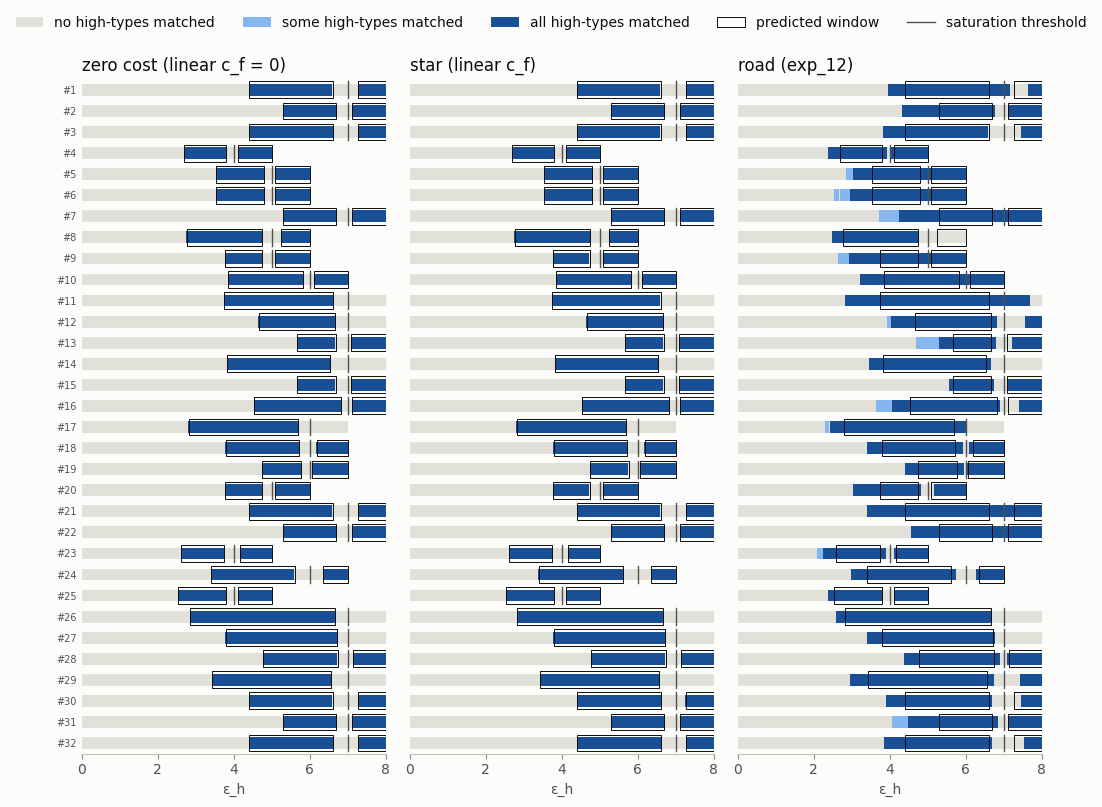

In [9]:
arms_present = [a for a in ARMS if a in set(points["arm"])]
order = pred.index.tolist()
y_of = {i: n for n, i in enumerate(order)}
x_max = points["eps_h"].max()

fig, axes = plt.subplots(1, len(arms_present), figsize=(3.4 * len(arms_present), 0.2 * len(order) + 1.3),
                         sharex=True, sharey=True, squeeze=False)
strip_h, box_h = 0.56, 0.8
for ax, arm in zip(axes.flat, arms_present):
    for instance_id, g in points[points["arm"] == arm].groupby("instance"):
        y, T_h, p = y_of[instance_id], windows[instance_id]["T_h"], pred.loc[instance_id]
        eps = g["eps_h"].to_numpy()
        edges = np.concatenate([[eps[0]], (eps[1:] + eps[:-1]) / 2, [eps[-1]]])
        for (x0, x1), k in zip(zip(edges[:-1], edges[1:]), g["n_high"]):
            color = MATCH_NONE if k == 0 else (MATCH_ALL if k == T_h else MATCH_SOME)
            ax.add_patch(Rectangle((x0, y - strip_h / 2), x1 - x0, strip_h, facecolor=color, edgecolor="none"))
        regions = [(p["eps_h_minus"], min(p["eps_h_plus"], p["L"]))]
        if np.isfinite(p["eps_h_bar"]):
            regions.append((max(p["eps_h_bar"], p["L"]), eps[-1]))
        for lo, hi in regions:
            if hi > lo:
                ax.add_patch(Rectangle((lo, y - box_h / 2), hi - lo, box_h, facecolor="none", edgecolor=INK, linewidth=0.7))
        ax.plot([p["L"]] * 2, [y - box_h / 2, y + box_h / 2], color=INK_SECONDARY, linewidth=1.0)
    ax.set_xlim(0, x_max)
    ax.set_title(ARM_LABELS[arm], loc="left", color=INK)
    ax.set_xlabel("ε_h")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

axes.flat[0].set_ylim(len(order) - 0.5, -0.5)
axes.flat[0].set_yticks(range(len(order)))
axes.flat[0].set_yticklabels([f"#{i}" for i in order], fontsize=7)
fig.legend(handles=[
    Patch(facecolor=MATCH_NONE, label="no high-types matched"),
    Patch(facecolor=MATCH_SOME, label="some high-types matched"),
    Patch(facecolor=MATCH_ALL, label="all high-types matched"),
    Patch(facecolor="none", edgecolor=INK, linewidth=0.7, label="predicted window"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold"),
], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5)

plt.tight_layout()
plt.savefig(FIG_DIR / "window_overview_13.png", bbox_inches="tight", dpi=300)
plt.show()

### Matches outside the predicted regions

Any linear-cost point where high types are matched outside the predicted regions should be a model tie, i.e. the platform is indifferent and the solver's choice is a tie-break (as in knife-edge instances with ε_ℓ = ε_ℓ^s).

In [10]:
# Linear-cost points where high types are matched outside the predicted inefficient regions: are they ties?
def in_predicted_region(instance_id, eps_h):
    p = pred.loc[instance_id]
    if p["eps_h_minus"] - SWITCH_TOL <= eps_h <= min(p["eps_h_plus"], p["L"]) + SWITCH_TOL:
        return True
    return bool(np.isfinite(p["eps_h_bar"]) and eps_h >= max(p["eps_h_bar"], p["L"]) - SWITCH_TOL)


def eps_l_saturation(w):
    # ε_ℓ^s: (EC4) gives a finite ε̄_h only for ε_ℓ < ε_ℓ^s; at ε_ℓ = ε_ℓ^s, B_ℓ = B_h past L (knife edge)
    F = w["T_l"] * w["n_l"] + w["T_h"] * w["n_h"]
    return w["K"] * (F - w["T_h"] * w["K"]) * w["sigma_l"] / (F * w["sigma_h"] - w["T_h"] * w["K"] * w["sigma_l"]) - w["n_l"]


knife = pd.Series({i: bool(np.isclose(w["eps_l"], eps_l_saturation(w))) for i, w in windows.items()}, name="knife_edge")
print(f"knife-edge instances (ε_ℓ = ε_ℓ^s): {sorted(knife.index[knife])}")

linear = points.query("arm != 'road' and n_high > 0")
unpredicted = linear[[not in_predicted_region(r.instance, r.eps_h) for r in linear.itertuples()]]
print("High types matched outside the predicted regions (linear-cost arms):")
unpredicted.groupby(["arm", "instance"]).agg(
    points=("eps_h", "size"), eps_from=("eps_h", "min"), eps_to=("eps_h", "max"),
    all_ties=("tie", "all"), all_matched_ok=("matched_ok", "all")).join(knife, on="instance")

knife-edge instances (ε_ℓ = ε_ℓ^s): []
High types matched outside the predicted regions (linear-cost arms):


,,points,eps_from,eps_to,all_ties,all_matched_ok,knife_edge
arm,instance,,,,,,


## Switch offsets by arm

Observed bracket midpoint minus the predicted threshold. With linear costs (zero, star) these should sit at 0 to within the bracket width (0.025 after bisection); the road arm (exp_12) shows the routing shift for comparison.

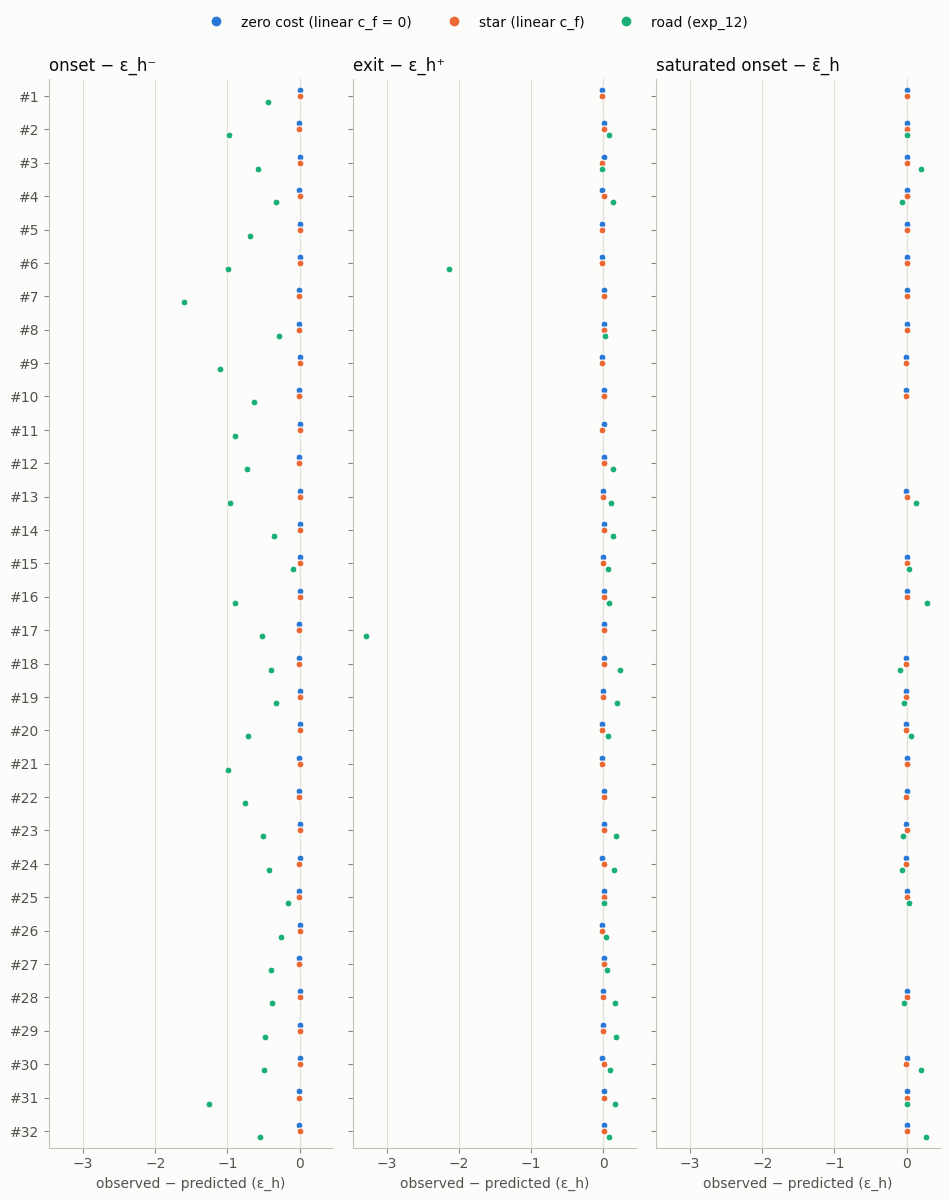

In [11]:
if len(switches):
    sw = switches.assign(offset=(switches["eps_before"] + switches["eps_after"]) / 2 - switches["predicted"])
    switch_order = [s for s in ["onset", "exit", "sat_onset"] if s in set(sw["switch"])]
    fig, axes = plt.subplots(1, len(switch_order), figsize=(3.2 * len(switch_order), 0.32 * sw["instance"].nunique() + 1.4),
                             sharex=True, sharey=True, squeeze=False)
    inst_order = sorted(sw["instance"].unique())
    y_of = {i: n for n, i in enumerate(inst_order)}
    offsets = {"zero": -0.18, "star": 0.0, "road": 0.18}
    for ax, name in zip(axes.flat, switch_order):
        d = sw.query("switch == @name")
        ax.axvline(0, color=AXIS, linewidth=0.8, zorder=0)
        for arm in ARMS:
            da = d[d["arm"] == arm]
            ax.plot(da["offset"], [y_of[i] + offsets[arm] for i in da["instance"]], "o", markersize=5,
                    color=ARM_COLORS[arm], markeredgecolor=SURFACE, markeredgewidth=0.8, label=ARM_LABELS[arm])
        ax.set_title({"onset": "onset − ε_h⁻", "exit": "exit − ε_h⁺", "sat_onset": "saturated onset − ε̄_h"}[name],
                     loc="left", color=INK)
        ax.grid(axis="x")
        ax.set_axisbelow(True)
        ax.set_xlabel("observed − predicted (ε_h)")
    axes.flat[0].set_yticks(range(len(inst_order)))
    axes.flat[0].set_yticklabels([f"#{i}" for i in inst_order])
    axes.flat[0].set_ylim(len(inst_order) - 0.5, -0.5)
    handles = [Line2D([], [], marker="o", linestyle="none", color=ARM_COLORS[a], label=ARM_LABELS[a])
               for a in ARMS if a in set(sw["arm"])]
    plt.tight_layout()
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(handles))
    plt.savefig(FIG_DIR / "switch_offsets.png", bbox_inches="tight", dpi=300)
    plt.show()

## Late exit past saturation: #11

On the road network, #11 keeps all three high types matched well past the predicted exit ε_h⁺ = 6.6 and past saturation (`L` = 7), until 7.70. Prop 3 rules this out. #11 has ε_ℓ ≥ ε_ℓ^s, so (EC4) gives ε̄_h = ∞: past ε_h⁺ the efficient set should be optimal for every ε_h. The star arm follows Prop 3 and exits at 6.6 exactly. Unlike #5/#29 in exp_11, this is not a second inefficient regime. It is the first window ending late: the road arm's window is extended at both ends, with an early onset and a late exit.

As in exp_11, at every solved ε_h this compares the **optimal** profit with the **efficient** profit (`forced_lower_bound`, the best the platform can do with the efficient set). Their difference is the value of matching the high types.

In [12]:
from matplotlib.ticker import FuncFormatter

SB_INSTANCES = [11]
MODEL_STEP = 0.001
EFFICIENT_COLOR = "#898781"
SHADE = "#ecebe7"
# thousands, keeping one decimal only when it is not a whole number of thousands (2.5k, not 2k)
thousands = FuncFormatter(lambda x, _: f"{x / 1e3:,.1f}".rstrip("0").rstrip(".") + "k")

rows, sigma_ell = [], {}
for arm, payload in jobs:
    instance_id = payload["instance_id"]
    if arm not in ("road", "star") or instance_id not in SB_INSTANCES:
        continue
    sigma_ell[instance_id] = payload["experiment_metadata"]["constants"]["sigma_ell"]
    high_ids = set(payload["high_ids"])
    for run in payload["runs"]:
        summary = run["summary"]
        primary = summary["platform_solve_result"]["primary_result"]
        rows.append({
            "arm": arm, "instance": instance_id, "eps_h": run["eps_h"],
            "n_high": len(set(primary["selected_intermediaries"]) & high_ids),
            "optimal": primary["platform_profit"],
            "efficient": summary["forced_lower_bound"],
            "high_profit": sum(v for t, v in primary["intermediary_profits"].items() if t in high_ids),
            "farmer_payments": sum(primary["farmer_payments"].values()),
            "rel_gap": summary["rel_gap"],
        })

sb_points = pd.DataFrame(rows).sort_values(["instance", "arm", "eps_h"]).reset_index(drop=True)
sb_points["value_of_matching_high"] = sb_points["optimal"] - sb_points["efficient"]
print(sb_points.groupby(["instance", "arm"]).size().rename("points").to_string())
print(f"max solver rel_gap: {sb_points['rel_gap'].max():.1e} (paper_bnb stops at 1e-4)")

# the efficient profit should also match the closed form (x_h = 0) in the star arm (c_f cancels from the profit)
check = sb_points.query("arm == 'star'")
err_eff = max(abs(profit_closed_form(windows[r.instance], r.eps_h, 0) * sigma_ell[r.instance] - r.efficient)
              / max(1.0, abs(r.efficient)) for r in check.itertuples())
print(f"closed form vs star arm, efficient set: max rel error {err_eff:.1e}")

model_rows = []
for i in SB_INSTANCES:
    w, T_h = windows[i], int(windows[i]["T_h"])
    grid = np.unique(np.concatenate([
        np.arange(0, sb_points.query("instance == @i")["eps_h"].max() + MODEL_STEP / 2, MODEL_STEP),
        pred.loc[i, ["eps_h_minus", "eps_h_plus", "L"]].to_numpy(dtype=float),
    ]))
    for e in grid:
        model_rows.append({
            "instance": i, "eps_h": e,
            "model_efficient": profit_closed_form(w, e, 0) * sigma_ell[i],
            "model_high": profit_closed_form(w, e, T_h) * sigma_ell[i],
        })
sb_model = pd.DataFrame(model_rows)
sb_model["model_value_of_matching_high"] = sb_model["model_high"] - sb_model["model_efficient"]
pred.loc[SB_INSTANCES].round(4)

instance  arm 
11        road    39
          star    33
max solver rel_gap: 3.1e-13 (paper_bnb stops at 1e-4)
closed form vs star arm, efficient set: max rel error 2.2e-13


,L,eps_h_minus,eps_h_plus,eps_h_bar
instance,,,,
11,7.0,3.7333,6.6,inf


### Optimal vs. efficient profit

From `L` − 1 to the end of the sweep. Left: the road network; right: the star arm. Shaded spans are where the solver matches the high types; the vertical line is `L`.

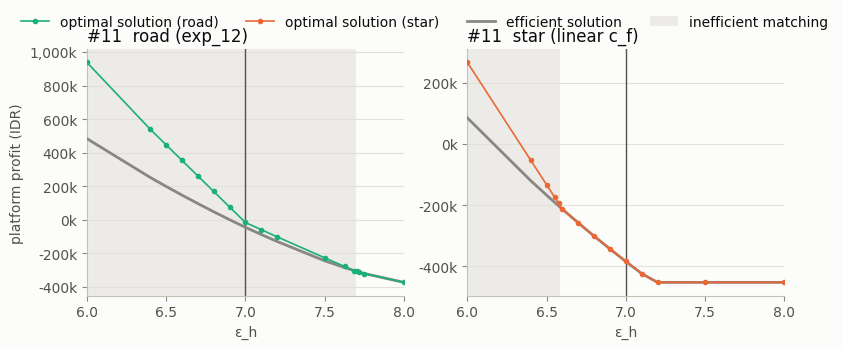

In [13]:
def shade_matched(ax, g):
    eps = g["eps_h"].to_numpy()
    edges = np.concatenate([[eps[0]], (eps[1:] + eps[:-1]) / 2, [eps[-1]]])
    for (x0, x1), k in zip(zip(edges[:-1], edges[1:]), g["n_high"]):
        if k > 0:
            ax.axvspan(x0, x1, color=SHADE, linewidth=0, zorder=0)

ZOOM_BELOW_L = 1

# one row per instance: road (left) and star (right)
fig, axes = plt.subplots(len(SB_INSTANCES), 2, figsize=(9, 3.2 * len(SB_INSTANCES)), squeeze=False,
                         gridspec_kw={"hspace": 0.35})
for row, i in enumerate(SB_INSTANCES):
    x_lo = pred.loc[i, "L"] - ZOOM_BELOW_L
    for col, arm in enumerate(["road", "star"]):
        ax = axes[row, col]
        g_all = sb_points.query("instance == @i and arm == @arm")
        # keep the neighbouring solved point on each side so shading and lines reach the axes edge
        k0 = max(0, int(np.searchsorted(g_all["eps_h"].to_numpy(), x_lo)) - 1)
        g = g_all.iloc[k0:]
        x_hi = g_all["eps_h"].max()
        mi = sb_model.query("instance == @i and eps_h >= @x_lo")

        # levels
        shade_matched(ax, g)
        ax.axvline(pred.loc[i, "L"], color=INK_SECONDARY, linewidth=1.0, zorder=1)
        visible = [g.loc[g["eps_h"] >= x_lo, ["optimal", "efficient"]].to_numpy().ravel()]
        ax.plot(g["eps_h"], g["efficient"], color=EFFICIENT_COLOR, linewidth=2, zorder=3)
        ax.plot(g["eps_h"], g["optimal"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3, zorder=4)
        lo, hi = np.min(np.concatenate(visible)), np.max(np.concatenate(visible))
        pad = 0.06 * (hi - lo)
        ax.set_xlim(x_lo, x_hi)
        ax.set_ylim(lo - pad, hi + pad)
        ax.yaxis.set_major_formatter(thousands)
        ax.set_title(f"#{i}  {ARM_LABELS[arm]}", loc="left", color=INK)
        ax.grid(axis="y")
        ax.set_axisbelow(True)

    axes[row, 0].set_ylabel("platform profit (IDR)")

for ax in axes[-1]:
    ax.set_xlabel("ε_h")

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="efficient solution"),
    Patch(facecolor=SHADE, label="inefficient matching"),
], loc="lower center", bbox_to_anchor=(0.5, 0.905), ncol=4)
plt.savefig(FIG_DIR / "late_exit_11_optimal_vs_efficient.png", bbox_inches="tight", dpi=300)
plt.show()

### The split of the transfers is not unique

In exp_11, the profit the platform leaves the matched high type was pinned down by its worst-case deviation, and its slope in ε_h was the budget's dual price η. In #11 that number is not identified. Between neighbouring ε_h, the total transferred to farmers and the matched high types moves exactly with the platform's profit. But how it is split between farmers and each of the three high types jumps by hundreds of thousands, in both arms. So the platform has many equally profitable solutions, and an individual high type's profit (or its slope) says nothing about the mechanism. The sections below therefore use only the platform's profits and their gap, which are unique.

In [14]:
# How the platform's transfers are split between farmers and the matched high types is not unique here:
# total transfers (farmer payments + matched high types' profit) move exactly with platform profit,
# but the split between farmers and each high type jumps around between neighbouring ε_h.
split_rows = []
for arm, p in jobs:
    if arm not in ("road", "star") or p["instance_id"] not in SB_INSTANCES:
        continue
    hi = set(p["high_ids"])
    for run in p["runs"]:
        pr = run["summary"]["platform_solve_result"]["primary_result"]
        matched_high = sorted(set(pr["selected_intermediaries"]) & hi)
        if len(matched_high) != len(hi):
            continue
        split_rows.append({"arm": arm, "eps_h": run["eps_h"], "platform_profit": pr["platform_profit"],
                           "farmer_payments": sum(pr["farmer_payments"].values()),
                           **{h: pr["intermediary_profits"][h] for h in matched_high}})
split = pd.DataFrame(split_rows).sort_values(["arm", "eps_h"]).reset_index(drop=True)
high_cols = sorted(set(split.columns) - {"arm", "eps_h", "platform_profit", "farmer_payments"})
split["high_profit"] = split[high_cols].sum(axis=1)
split["transfers"] = split["farmer_payments"] + split["high_profit"]

# between the coarse points (step 0.5) the change in transfers should equal minus the change in platform profit
# when the collection cost of the chosen set does not change
coarse = split[np.isclose(split["eps_h"] * 2, np.round(split["eps_h"] * 2))]
d = coarse.groupby("arm")[["platform_profit", "transfers", "farmer_payments", "high_profit"] + high_cols].diff().dropna()
print("change between consecutive coarse points (all high types matched):")
display(coarse.loc[d.index, ["arm", "eps_h"]].join(d.round(0)))
print("transfers + platform profit is constant (same collection cost): "
      f"max |Δ(transfers + profit)| = {(d['transfers'] + d['platform_profit']).abs().max():,.0f}")

change between consecutive coarse points (all high types matched):


,arm,eps_h,platform_profit,transfers,farmer_payments,high_profit,goofy_bell,practical_elion,unruffled_elbakyan
3,road,3.5,-561227.0,561227.0,494360.0,66867.0,64143.0,-125693.0,128418.0
9,road,4.0,-536525.0,536525.0,-256588.0,793113.0,106564.0,228255.0,458295.0
10,road,4.5,-526015.0,526015.0,449940.0,76075.0,113413.0,110580.0,-147919.0
11,road,5.0,-517005.0,517005.0,-110343.0,627348.0,87216.0,84578.0,455553.0
12,road,5.5,-508605.0,508605.0,583902.0,-75297.0,-116331.0,-135538.0,176572.0
13,road,6.0,-507875.0,507875.0,-699895.0,1207770.0,427718.0,458148.0,321905.0
15,road,6.5,-491226.0,491226.0,1774455.0,-1283229.0,-484759.0,-331184.0,-467286.0
20,road,7.0,-462260.0,462260.0,-296464.0,758724.0,-730156.0,-210730.0,1699610.0
23,road,7.5,-210455.0,210455.0,-1934632.0,2145088.0,1073142.0,591951.0,479995.0
31,star,4.5,-400000.0,400000.0,1333333.0,-933333.0,-666667.0,933333.0,-1200000.0


transfers + platform profit is constant (same collection cost): max |Δ(transfers + profit)| = 0


### Summary figure: the late exit (#11)

Top: profit of the efficient set and of the solver's optimum. Bottom: their gap, the value of matching the high types. The dashed line is the predicted exit ε_h⁺; the solid line is `L`. In the star arm the gap closes at ε_h⁺, as Prop 3 predicts. On the road network it is still positive there (about 200k) and stays positive through saturation, closing only at about 7.70.

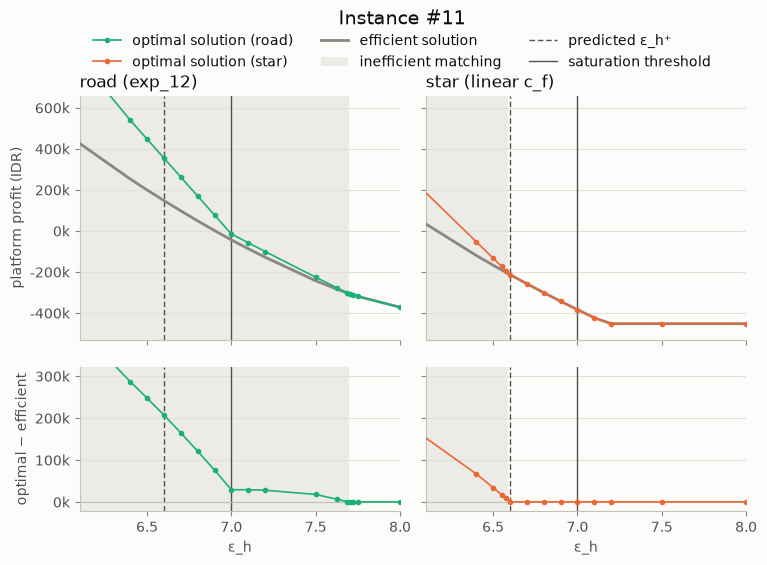

,arm,exit_bracket,predicted_exit,L,value_at_eps_h_plus,value_at_L
0,road,"(7.6875, 7.7031]",6.6,7.0,206891.5383,28880.0942
1,star,"(6.5750, 6.6000]",6.6,7.0,-0.0000,0.0000


In [24]:
SUMMARY_INSTANCE = SB_INSTANCES[0]
i = SUMMARY_INSTANCE
x_lo = min(pred.loc[i, "eps_h_plus"], pred.loc[i, "L"]) - 0.5

fig, axes = plt.subplots(2, 2, figsize=(8.6, 5.4), sharex="col", sharey="row",
                         gridspec_kw={"height_ratios": [2.2, 1.3], "hspace": 0.14, "wspace": 0.08})
for col, arm in enumerate(["road", "star"]):
    g_all = sb_points.query("instance == @i and arm == @arm")
    k0 = max(0, int(np.searchsorted(g_all["eps_h"].to_numpy(), x_lo)) - 1)
    g = g_all.iloc[k0:]
    ax_lvl, ax_gap = axes[:, col]
    for ax in axes[:, col]:
        shade_matched(ax, g)
        for x, style in [(pred.loc[i, "eps_h_plus"], (0, (4, 2))), (pred.loc[i, "L"], "-")]:
            ax.axvline(x, color=INK_SECONDARY, linewidth=1.0, linestyle=style, zorder=1)
        ax.grid(axis="y")
        ax.set_axisbelow(True)

    # levels
    ax_lvl.plot(g["eps_h"], g["efficient"], color=EFFICIENT_COLOR, linewidth=2, zorder=3)
    ax_lvl.plot(g["eps_h"], g["optimal"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3, zorder=4)
    ax_lvl.set_title(ARM_LABELS[arm], loc="left", color=INK)

    # gap: the value of matching the high types
    ax_gap.axhline(0, color=AXIS, linewidth=0.8, zorder=1)
    ax_gap.plot(g["eps_h"], g["value_of_matching_high"], color=ARM_COLORS[arm], linewidth=1.2,
                marker="o", markersize=3, zorder=4)
    ax_gap.set_xlabel("ε_h")
    ax_gap.set_xlim(x_lo, g_all["eps_h"].max())


# shared y-ranges, fitted to what is visible
def fit_ylim(ax_row, values, lower_pad=0.08, upper_pad=0.12, floor=None):
    lo, hi = np.nanmin(values), np.nanmax(values)
    if floor is not None:
        lo = min(lo, floor)
    span = hi - lo if hi > lo else max(1.0, abs(hi))
    ax_row.set_ylim(lo - lower_pad * span, hi + upper_pad * span)


window = sb_points.query("instance == @i and eps_h >= @x_lo")
fit_ylim(axes[0, 0], np.concatenate([window["optimal"], window["efficient"]]))
fit_ylim(axes[1, 0], window["value_of_matching_high"], floor=0.0)
for ax, label in [(axes[0, 0], "platform profit (IDR)"), (axes[1, 0], "optimal − efficient")]:
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(thousands)

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="efficient solution"),
    Patch(facecolor=SHADE, label="inefficient matching"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, linestyle=(0, (4, 2)), label="predicted ε_h⁺"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold"),
], loc="lower center", bbox_to_anchor=(0.5, 0.905), ncol=3)
fig.suptitle(f"Instance #{i}", fontsize=14, color=INK, y=1.04)
plt.savefig(FIG_DIR / f"instance_{i}_profit.png", bbox_inches="tight", dpi=300)
plt.show()

# where each arm exits, and the value of matching the high types on the way
exits = []
for arm in ["road", "star"]:
    g = sb_points.query("instance == @i and arm == @arm").reset_index(drop=True)
    k = max(j for j in range(1, len(g)) if g.n_high[j - 1] > 0 and g.n_high[j] == 0)
    exits.append({"arm": arm, "exit_bracket": f"({g.eps_h[k - 1]:.4f}, {g.eps_h[k]:.4f}]",
                  "predicted_exit": pred.loc[i, "eps_h_plus"], "L": pred.loc[i, "L"],
                  "value_at_eps_h_plus": float(np.interp(pred.loc[i, "eps_h_plus"], g.eps_h, g.value_of_matching_high)),
                  "value_at_L": float(np.interp(pred.loc[i, "L"], g.eps_h, g.value_of_matching_high))})
pd.DataFrame(exits).round(4)